# 1. Project Introduction
In this project, I want to explore how screen habits and lifestyle choices relate to sleep. I will use the Digital Insomnia dataset, which contains information about screen time, caffeine consumption, bedtime, sleep duration, and other factors.
Using machine learning, I will try to predict sleep debt categories and understand which features are most important.

# 2. Research Question
**Can machine learning predict a person's sleep debt category based on their screen habits, lifestyle choices, and sleep-related features?**

# 3. Project Objectives
- Explore and understand the dataset.
- Clean and prepare the data for machine learning.
- Build and compare two models: SVM and Random Forest.
- Evaluate their performance using different metrics.
- Identify the most important features influencing the predictions.

In [390]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import scale
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC 
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score
)
import matplotlib.pyplot as plt

# Data loading and exploration

In [391]:
data = pd.read_csv("screen_time.csv")
data = data.drop(columns=["next_day_fatigue_score","user_id"])
data

,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,...,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,sleep_debt_category
0,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,264,...,73,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,Moderate
1,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,18,...,25,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,No Debt
2,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,62,...,48,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,Mild
3,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,42,...,9,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,No Debt
4,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,78,...,5,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,Mild
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,35,Male,Early Bird,Retired,22.16,76,Gaming,83,False,14,...,1,68.0,16.1,33.8,6.57,15.5,14.0,3,81.7,Mild
8496,33,Female,Intermediate,Freelancer,23.14,102,E-Reading,55,False,3,...,28,71.1,41.0,14.8,7.00,20.3,20.4,2,81.9,Mild
8497,40,Female,Intermediate,Student,0.76,52,Streaming,87,True,65,...,2,71.9,41.2,16.8,6.51,17.3,17.2,0,77.8,Mild
8498,16,Male,Night Owl,Student,1.60,53,Gaming,72,True,95,...,5,67.2,23.5,25.6,7.47,12.4,18.7,3,87.3,Mild


In [392]:
print(data.shape)
print(data.info())
print(data.isnull().sum())
print(data.describe())

(8500, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         8500 non-null   int64  
 1   gender                      8500 non-null   object 
 2   chronotype                  8500 non-null   object 
 3   occupation                  8500 non-null   object 
 4   bedtime_hour                8500 non-null   float64
 5   screen_time_before_bed_min  8500 non-null   int64  
 6   primary_app_category        8500 non-null   object 
 7   screen_brightness_pct       8500 non-null   int64  
 8   blue_light_filter_on        8500 non-null   bool   
 9   caffeine_intake_mg          8500 non-null   int64  
 10  caffeine_last_hour          8500 non-null   float64
 11  physical_activity_min       8500 non-null   int64  
 12  room_temperature_f          8500 non-null   float64
 13  ambient_noise_db      

# Data preprocessing

In [393]:
x = data.drop("sleep_debt_category", axis=1)
y = data["sleep_debt_category"]

In [394]:
data["chronotype"].unique()

array(['Intermediate', 'Night Owl', 'Early Bird'], dtype=object)

In [395]:
data["occupation"].unique()


array(['Student', 'Professional', 'Retired', 'Unemployed', 'Freelancer'],
      dtype=object)

In [396]:
data["primary_app_category"].unique()


array(['Social Media', 'Short-Form Video', 'Messaging', 'Streaming',
       'E-Reading', 'Gaming', 'News'], dtype=object)

In [397]:
ohe = OneHotEncoder(sparse_output=False).set_output(transform='pandas')
oheT = ohe.fit_transform(x[['chronotype']])
oheT2 = ohe.fit_transform(x[["occupation"]])
oheT3 = ohe.fit_transform(x[["primary_app_category"]])
oheT

,chronotype_Early Bird,chronotype_Intermediate,chronotype_Night Owl
0,0.0,1.0,0.0
1,0.0,1.0,0.0
2,0.0,0.0,1.0
3,0.0,1.0,0.0
4,1.0,0.0,0.0
...,...,...,...
8495,1.0,0.0,0.0
8496,0.0,1.0,0.0
8497,0.0,1.0,0.0
8498,0.0,0.0,1.0


In [398]:
le = LabelEncoder()
x["gender"] = le.fit_transform(x["gender"])
x["blue_light_filter_on"] = le.fit_transform(x["blue_light_filter_on"])
x

,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct
0,32,0,Intermediate,Student,23.94,102,Social Media,100,0,264,21.5,73,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7
1,26,0,Intermediate,Student,0.06,14,Short-Form Video,87,1,18,12.6,25,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9
2,34,1,Night Owl,Professional,1.48,58,Messaging,76,1,62,16.5,48,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6
3,43,0,Intermediate,Professional,22.42,48,Social Media,56,0,42,18.9,9,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9
4,25,1,Early Bird,Professional,22.43,29,Streaming,96,1,78,16.3,5,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,35,1,Early Bird,Retired,22.16,76,Gaming,83,0,14,23.0,1,68.0,16.1,33.8,6.57,15.5,14.0,3,81.7
8496,33,0,Intermediate,Freelancer,23.14,102,E-Reading,55,0,3,19.4,28,71.1,41.0,14.8,7.00,20.3,20.4,2,81.9
8497,40,0,Intermediate,Student,0.76,52,Streaming,87,1,65,13.1,2,71.9,41.2,16.8,6.51,17.3,17.2,0,77.8
8498,16,1,Night Owl,Student,1.60,53,Gaming,72,1,95,19.9,5,67.2,23.5,25.6,7.47,12.4,18.7,3,87.3


In [399]:
x = x.drop(columns=[
    "chronotype",
    "occupation",
    "primary_app_category",
    
])

In [400]:
x = pd.concat([x, oheT, oheT2, oheT3], axis=1)
x

,age,gender,bedtime_hour,screen_time_before_bed_min,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,...,occupation_Retired,occupation_Student,occupation_Unemployed,primary_app_category_E-Reading,primary_app_category_Gaming,primary_app_category_Messaging,primary_app_category_News,primary_app_category_Short-Form Video,primary_app_category_Social Media,primary_app_category_Streaming
0,32,0,23.94,102,100,0,264,21.5,73,73.5,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,26,0,0.06,14,87,1,18,12.6,25,66.8,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,34,1,1.48,58,76,1,62,16.5,48,68.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,43,0,22.42,48,56,0,42,18.9,9,72.3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,25,1,22.43,29,96,1,78,16.3,5,80.1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,35,1,22.16,76,83,0,14,23.0,1,68.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
8496,33,0,23.14,102,55,0,3,19.4,28,71.1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8497,40,0,0.76,52,87,1,65,13.1,2,71.9,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
8498,16,1,1.60,53,72,1,95,19.9,5,67.2,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [401]:
print(x.shape)
print(x.dtypes)
print(x.isnull().sum())
print(y.value_counts())

(8500, 32)
age                                        int64
gender                                     int64
bedtime_hour                             float64
screen_time_before_bed_min                 int64
screen_brightness_pct                      int64
blue_light_filter_on                       int64
caffeine_intake_mg                         int64
caffeine_last_hour                       float64
physical_activity_min                      int64
room_temperature_f                       float64
ambient_noise_db                         float64
sleep_onset_latency_min                  float64
total_sleep_hours                        float64
rem_sleep_pct                            float64
deep_sleep_pct                           float64
awakenings_count                           int64
sleep_efficiency_pct                     float64
chronotype_Early Bird                    float64
chronotype_Intermediate                  float64
chronotype_Night Owl                     float64
occupatio

In [402]:
print(y.value_counts())
print(y.value_counts(normalize=True) * 100)
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state= 42, stratify=y)

sleep_debt_category
Mild        4393
Moderate    2361
No Debt     1721
Severe        25
Name: count, dtype: int64
sleep_debt_category
Mild        51.682353
Moderate    27.776471
No Debt     20.247059
Severe       0.294118
Name: proportion, dtype: float64


# scaling data 

In [403]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Training and processing  the SVM model 

In [404]:
svm_model = SVC(kernel="rbf", class_weight="balanced")

svm_model.fit(x_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


In [405]:
y_pred = svm_model.predict(x_test_scaled)
y_pred

array(['No Debt', 'Mild', 'Mild', ..., 'Moderate', 'Mild', 'Mild'],
      shape=(2550,), dtype=object)

Accuracy: 0.7827450980392157
Macro F1-score: 0.6434176750510789
              precision    recall  f1-score   support

        Mild       0.84      0.72      0.78      1318
    Moderate       0.76      0.86      0.81       708
     No Debt       0.70      0.85      0.76       516
      Severe       1.00      0.12      0.22         8

    accuracy                           0.78      2550
   macro avg       0.83      0.64      0.64      2550
weighted avg       0.79      0.78      0.78      2550



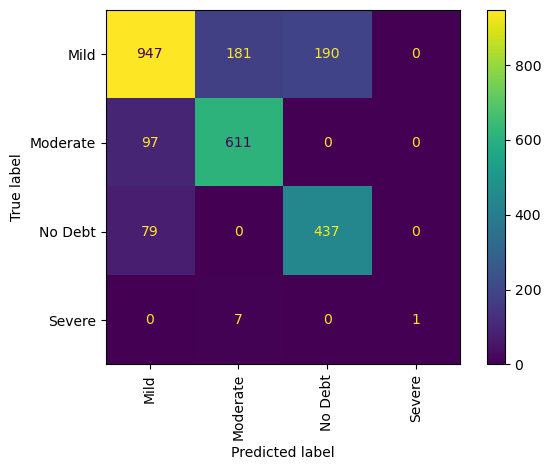

In [406]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Macro F1-score:", f1_score(
    y_test, y_pred, average="macro", zero_division=0
))

print(classification_report(
    y_test, y_pred, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation="vertical"
)
plt.tight_layout()
plt.show()

# inspecting the confusion matrix 

In [407]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No Debt", "Mild", "Moderate", "Severe"]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual No Debt", "Actual Mild",
           "Actual Moderate", "Actual Severe"],
    columns=["Pred No Debt", "Pred Mild",
             "Pred Moderate", "Pred Severe"]
)

print(cm_df)

                 Pred No Debt  Pred Mild  Pred Moderate  Pred Severe
Actual No Debt            437         79              0            0
Actual Mild               190        947            181            0
Actual Moderate             0         97            611            0
Actual Severe               0          0              7            1


# Tuning the SVM with GridSearchCV

In [408]:
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.1, 1]
}
svm = SVC(kernel="rbf", class_weight="balanced")
grid = GridSearchCV(
    svm,
    param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid.fit(x_train_scaled, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV macro F1:", grid.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'C': 1, 'gamma': 0.01}
Best CV macro F1: 0.6283487592758988


In [409]:
best_model = grid.best_estimator_

y_pred = best_model.predict(x_test_scaled)

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

        Mild       0.86      0.71      0.78      1318
    Moderate       0.78      0.87      0.82       708
     No Debt       0.69      0.87      0.77       516
      Severe       0.40      0.50      0.44         8

    accuracy                           0.79      2550
   macro avg       0.68      0.74      0.70      2550
weighted avg       0.80      0.79      0.79      2550



In [410]:
print("Best parameters:", grid.best_params_)
print("Best CV macro F1:", grid.best_score_)

Best parameters: {'C': 1, 'gamma': 0.01}
Best CV macro F1: 0.6283487592758988


# comparing it against the random forest model 

In [411]:

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(x_train, y_train)

rf_pred = rf_model.predict(x_test)

print(classification_report(
    y_test, rf_pred, zero_division=0
))

print("Random Forest macro F1:",
      f1_score(y_test, rf_pred, average="macro"))

              precision    recall  f1-score   support

        Mild       0.96      0.99      0.97      1318
    Moderate       0.97      0.99      0.98       708
     No Debt       1.00      0.89      0.94       516
      Severe       0.00      0.00      0.00         8

    accuracy                           0.97      2550
   macro avg       0.73      0.72      0.72      2550
weighted avg       0.96      0.97      0.96      2550

Random Forest macro F1: 0.7231567770763062


In [412]:
print(
    data.groupby("sleep_debt_category")["total_sleep_hours"]
    .agg(["min", "max", "mean", "median"])
)

                      min   max      mean  median
sleep_debt_category                              
Mild                 5.52  8.00  6.854120    6.78
Moderate             4.12  7.00  5.956069    5.86
No Debt              6.51  9.69  7.746903    7.62
Severe               3.91  5.49  4.826800    4.71


# comparing the results and anaysing them

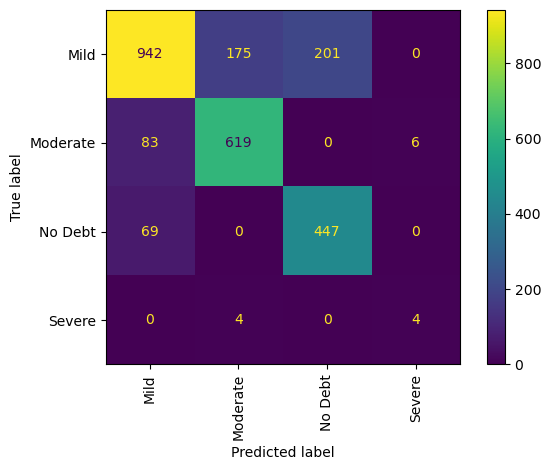

In [413]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation="vertical"
)
plt.tight_layout()
plt.show()

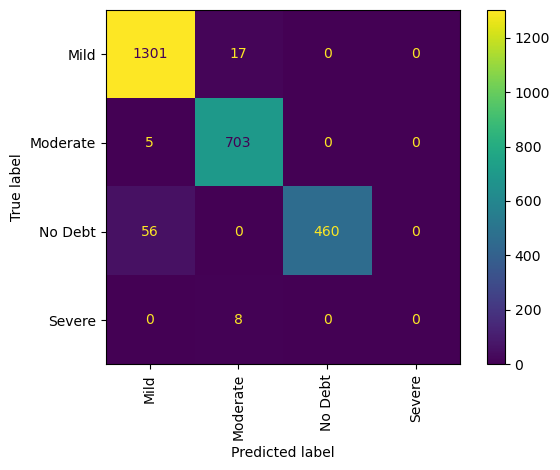

In [414]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    xticks_rotation="vertical"
)
plt.tight_layout()
plt.show()

In [415]:
severe_data = data[data["sleep_debt_category"] == "Severe"]

print("Severe records:", len(severe_data))

print(severe_data.describe())

Severe records: 25
             age  bedtime_hour  screen_time_before_bed_min  \
count  25.000000      25.00000                   25.000000   
mean   25.480000       2.39200                   63.120000   
std     9.421253       4.47191                   45.821502   
min    16.000000       0.17000                   15.000000   
25%    16.000000       1.10000                   32.000000   
50%    21.000000       1.54000                   48.000000   
75%    33.000000       1.94000                   87.000000   
max    47.000000      23.55000                  232.000000   

       screen_brightness_pct  caffeine_intake_mg  caffeine_last_hour  \
count              25.000000           25.000000           25.000000   
mean               67.920000          123.240000           17.228000   
std                18.087565          118.387527            3.637939   
min                17.000000           13.000000           11.800000   
25%                63.000000           30.000000           14.

In [416]:
data.groupby("sleep_debt_category").agg({
    "screen_time_before_bed_min": "mean",
    "screen_brightness_pct": "mean",
    "caffeine_intake_mg": "mean",
    "total_sleep_hours": "mean",
    "physical_activity_min": "mean",
    "ambient_noise_db": "mean"
}).round(2)

,screen_time_before_bed_min,screen_brightness_pct,caffeine_intake_mg,total_sleep_hours,physical_activity_min,ambient_noise_db
sleep_debt_category,,,,,,
Mild,53.04,68.39,78.31,6.85,29.27,35.05
Moderate,59.05,70.50,93.32,5.96,31.21,35.26
No Debt,48.13,67.38,63.69,7.75,28.96,34.30
Severe,63.12,67.92,123.24,4.83,35.48,39.59


# visualizing the data to get a better understanding of the sever cases 

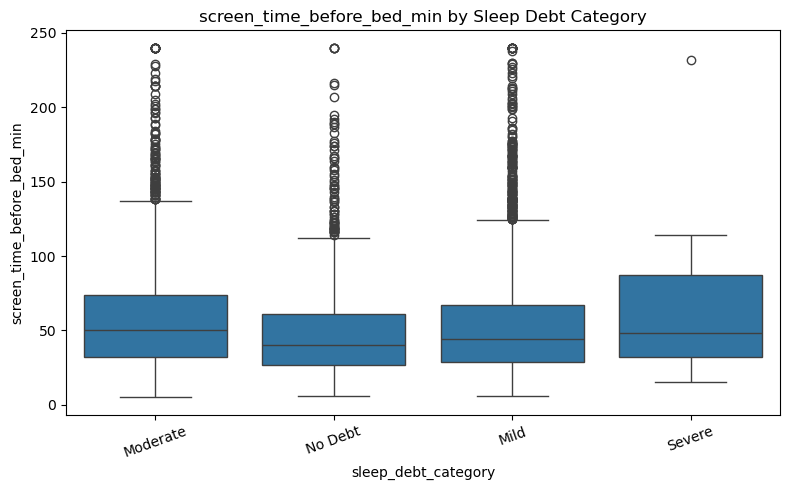

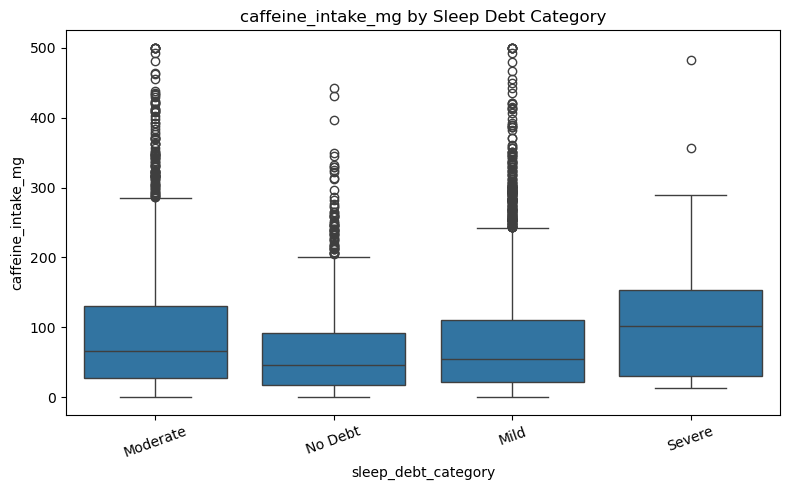

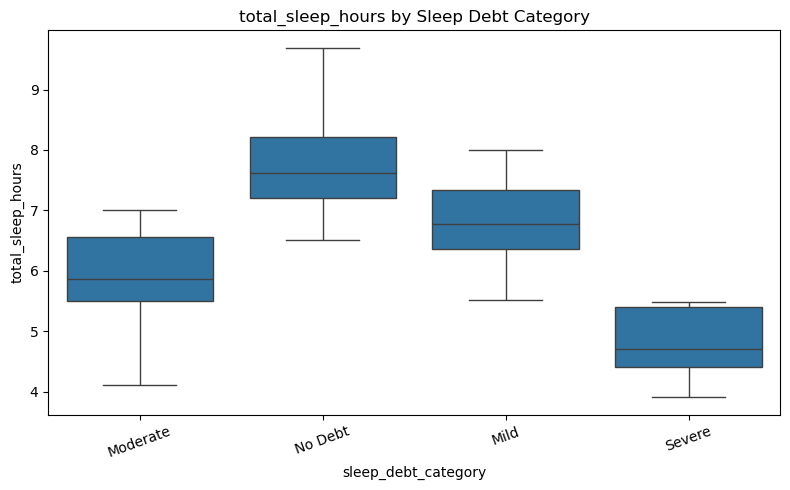

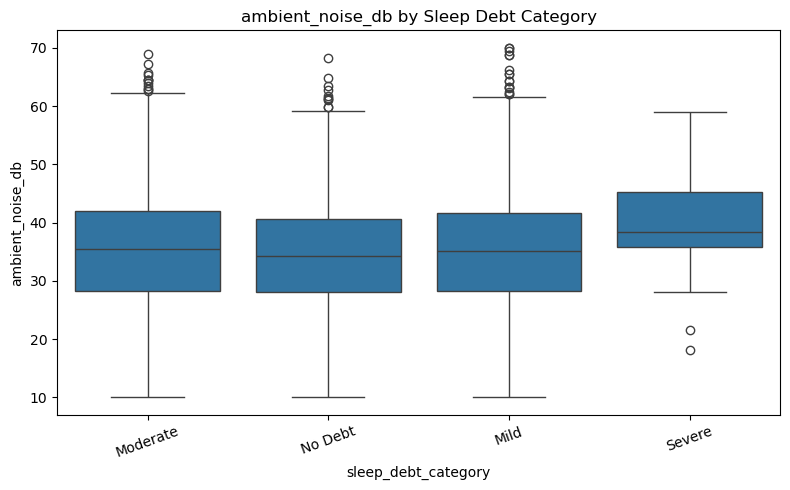

In [417]:


features = [
    "screen_time_before_bed_min",
    "caffeine_intake_mg",
    "total_sleep_hours",
    "ambient_noise_db"
]

for feature in features:
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=data,
        x="sleep_debt_category",
        y=feature
    )
    plt.title(f"{feature} by Sleep Debt Category")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

# Investigating class imbalance

In [418]:
print("Training distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training distribution:
sleep_debt_category
Mild        3075
Moderate    1653
No Debt     1205
Severe        17
Name: count, dtype: int64

Testing distribution:
sleep_debt_category
Mild        1318
Moderate     708
No Debt      516
Severe         8
Name: count, dtype: int64


# using the SMOTE technique for balancing the data 

In [419]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

x_train_sm, y_train_sm = smote.fit_resample(
    x_train_scaled,
    y_train
)

print(y_train_sm.value_counts())

sleep_debt_category
Mild        3075
Moderate    3075
No Debt     3075
Severe      3075
Name: count, dtype: int64


now i will train the SVM model again on the balanced data

In [420]:
svm_smote = SVC(
    kernel="rbf",
    random_state=42
)

svm_smote.fit(x_train_sm, y_train_sm)

svm_smote_pred = svm_smote.predict(x_test_scaled)

In [421]:
print(classification_report(
    y_test,
    svm_smote_pred,
    zero_division=0
))

print("Macro F1:",
      f1_score(y_test, svm_smote_pred,
               average="macro"))

              precision    recall  f1-score   support

        Mild       0.81      0.78      0.79      1318
    Moderate       0.78      0.82      0.80       708
     No Debt       0.75      0.79      0.77       516
      Severe       1.00      0.12      0.22         8

    accuracy                           0.79      2550
   macro avg       0.84      0.63      0.65      2550
weighted avg       0.79      0.79      0.79      2550

Macro F1: 0.6469133697165375


then i will train the random forest again 

In [422]:
rf_smote = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(x_train_sm, y_train_sm)

rf_smote_pred = rf_smote.predict(x_test_scaled)

print(classification_report(
    y_test,
    rf_smote_pred,
    zero_division=0
))

print("Macro F1:",
      f1_score(y_test, rf_smote_pred,
               average="macro"))

              precision    recall  f1-score   support

        Mild       0.98      0.96      0.97      1318
    Moderate       0.94      1.00      0.97       708
     No Debt       0.98      0.95      0.96       516
      Severe       0.00      0.00      0.00         8

    accuracy                           0.97      2550
   macro avg       0.72      0.73      0.73      2550
weighted avg       0.96      0.97      0.97      2550

Macro F1: 0.7255973967565631


after analysing the results i relised that the SMOTE didn't really help the random forst model to ditinguish the sever cases so i will try to run another models without the sever cases 

# experiment 2 

In [423]:
data_3class = data[
    data["sleep_debt_category"] != "Severe"
].copy()

print(data_3class["sleep_debt_category"].value_counts())

sleep_debt_category
Mild        4393
Moderate    2361
No Debt     1721
Name: count, dtype: int64


In [424]:
x3 = data_3class.drop("sleep_debt_category", axis=1)
y3 = data_3class["sleep_debt_category"]



# encoding 

In [425]:
x3 = data_3class.drop("sleep_debt_category", axis=1)
y3 = data_3class["sleep_debt_category"]

# One-Hot Encoding
ohe1 = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
ohe2 = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
ohe3 = OneHotEncoder(sparse_output=False).set_output(transform="pandas")

oheTT = ohe1.fit_transform(x3[["chronotype"]])
oheTT2 = ohe2.fit_transform(x3[["occupation"]])
oheTT3 = ohe3.fit_transform(x3[["primary_app_category"]])

# Label Encoding
le = LabelEncoder()

x3["gender"] = le.fit_transform(x3["gender"])
x3["blue_light_filter_on"] = le.fit_transform(
    x3["blue_light_filter_on"]
)
x3 = x3.drop(columns=[
    "chronotype",
    "occupation",
    "primary_app_category"
])
x3 = pd.concat([x3, oheTT, oheTT2, oheTT3], axis=1)


In [426]:
x3

,age,gender,bedtime_hour,screen_time_before_bed_min,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,...,occupation_Retired,occupation_Student,occupation_Unemployed,primary_app_category_E-Reading,primary_app_category_Gaming,primary_app_category_Messaging,primary_app_category_News,primary_app_category_Short-Form Video,primary_app_category_Social Media,primary_app_category_Streaming
0,32,0,23.94,102,100,0,264,21.5,73,73.5,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,26,0,0.06,14,87,1,18,12.6,25,66.8,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,34,1,1.48,58,76,1,62,16.5,48,68.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,43,0,22.42,48,56,0,42,18.9,9,72.3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,25,1,22.43,29,96,1,78,16.3,5,80.1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,35,1,22.16,76,83,0,14,23.0,1,68.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
8496,33,0,23.14,102,55,0,3,19.4,28,71.1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8497,40,0,0.76,52,87,1,65,13.1,2,71.9,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
8498,16,1,1.60,53,72,1,95,19.9,5,67.2,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [427]:
x3_train, x3_test, y3_train, y3_test = train_test_split(
    x3, y3,
    test_size=0.3,
    random_state=42,
    stratify=y3
)

scaler3 = StandardScaler()

x3_train_scaled = scaler3.fit_transform(x3_train)
x3_test_scaled = scaler3.transform(x3_test)

# training the svm 

In [428]:
svm3 = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=42
)

svm3.fit(x3_train_scaled, y3_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


In [429]:
y3_pred_svm = svm3.predict(x3_test_scaled)

In [430]:
print(classification_report(y3_test, y3_pred_svm))
print(confusion_matrix(y3_test, y3_pred_svm))

              precision    recall  f1-score   support

        Mild       0.85      0.73      0.78      1318
    Moderate       0.77      0.86      0.82       709
     No Debt       0.71      0.85      0.77       516

    accuracy                           0.79      2543
   macro avg       0.78      0.81      0.79      2543
weighted avg       0.80      0.79      0.79      2543

[[957 181 180]
 [ 96 613   0]
 [ 78   0 438]]


# training the random forest model 

In [431]:
rf3 = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf3.fit(x3_train, y3_train)

y3_pred_rf = rf3.predict(x3_test)

print(classification_report(y3_test, y3_pred_rf))
print(confusion_matrix(y3_test, y3_pred_rf))

              precision    recall  f1-score   support

        Mild       0.98      0.99      0.98      1318
    Moderate       0.98      1.00      0.99       709
     No Debt       1.00      0.96      0.98       516

    accuracy                           0.98      2543
   macro avg       0.99      0.98      0.98      2543
weighted avg       0.98      0.98      0.98      2543

[[1301   17    0]
 [   2  707    0]
 [  21    0  495]]


the random forest had a very high accuraccy so we should investigate it 

In [432]:
feature_importance = pd.DataFrame({
    "Feature": x3_train.columns,
    "Importance": rf3.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                       Feature  Importance
12           total_sleep_hours    0.423482
0                          age    0.149012
2                 bedtime_hour    0.055850
11     sleep_onset_latency_min    0.039584
6           caffeine_intake_mg    0.027553
16        sleep_efficiency_pct    0.025732
3   screen_time_before_bed_min    0.025618
10            ambient_noise_db    0.025451
7           caffeine_last_hour    0.024132
13               rem_sleep_pct    0.024016
9           room_temperature_f    0.023739
14              deep_sleep_pct    0.022828
4        screen_brightness_pct    0.022579
8        physical_activity_min    0.022104
19        chronotype_Night Owl    0.017755


The feature importance analysis shows that total_sleep_hours has an importance score of approximately 42.35%, making it the most influential feature in the Random Forest model. This does not mean it explains 42.35% of the target variable.

so i will train another model that can help me undestand how much the model depends on total_sleep_hours for the prediction 

In [433]:
x3_train_no_sleep = x3_train.drop(columns=["total_sleep_hours"])
x3_test_no_sleep = x3_test.drop(columns=["total_sleep_hours"])

In [434]:
rf_no_sleep = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_no_sleep.fit(x3_train_no_sleep, y3_train)

y3_pred_no_sleep = rf_no_sleep.predict(x3_test_no_sleep)

print(classification_report(y3_test, y3_pred_no_sleep))

              precision    recall  f1-score   support

        Mild       0.54      0.86      0.66      1318
    Moderate       0.54      0.28      0.37       709
     No Debt       0.39      0.07      0.12       516

    accuracy                           0.53      2543
   macro avg       0.49      0.40      0.38      2543
weighted avg       0.51      0.53      0.47      2543



Removing total_sleep_hours caused a significant decrease in model performance. This suggests that the model relies heavily on this feature. However, we still need to investigate how the target variable was generated before determining whether this represents target leakage.

so for now i will investigate the relation between sleep duration and the target

In [435]:
print(
    data_3class.groupby("sleep_debt_category")["total_sleep_hours"]
    .describe()
    .round(2)
)

                      count  mean   std   min   25%   50%   75%   max
sleep_debt_category                                                  
Mild                 4393.0  6.85  0.59  5.52  6.36  6.78  7.34  8.00
Moderate             2361.0  5.96  0.62  4.12  5.51  5.86  6.56  7.00
No Debt              1721.0  7.75  0.60  6.51  7.21  7.62  8.22  9.69


so from the output We can see a clear pattern:
- No Debt: People sleep the most, averaging 7.75 hours.
- Mild: People sleep an average of 6.85 hours.
- Moderate: People sleep the least, averaging 5.96 hours.

and that shows that less sleep is generally associated with more sleep debt


but there is another interestig discovery :
if you look at the minimum and maximum values you may realize that the sleeping time range overlaps This means sleep duration alone doesn't perfectly determine someone's category 

# conclusion 

One thing is already clear: removing 'total_sleep_hours' reduced accuracy from 98% to 53%. That's strong evidence that the feature is extremely influential, but it does not prove data leakage.
so actually i think that 'total_sleep_hours' is a very powerful predictive feature  but there is still a possible target leakage that i will investigate 


# final experiment

Let's build a model using only behavioral feature

In [436]:
physiological_features = [
    "total_sleep_hours",
    "sleep_efficiency_pct",
    "sleep_onset_latency_min",
    "rem_sleep_pct",
    "deep_sleep_pct"
]

x3_train_behavior = x3_train.drop(
    columns=physiological_features
)

x3_test_behavior = x3_test.drop(
    columns=physiological_features
)

In [437]:
rf_behavior = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_behavior.fit(x3_train_behavior, y3_train)

y3_pred_behavior = rf_behavior.predict(x3_test_behavior)

print(classification_report(y3_test, y3_pred_behavior))

              precision    recall  f1-score   support

        Mild       0.54      0.86      0.66      1318
    Moderate       0.52      0.25      0.34       709
     No Debt       0.44      0.07      0.12       516

    accuracy                           0.53      2543
   macro avg       0.50      0.40      0.37      2543
weighted avg       0.51      0.53      0.46      2543



oh, so the output confirms a very importent detail about the dataset because when we trained the model using only behavioral features we got 98.4% accuracy but without total_sleep_hours we only got 53% and now with only behavioral features we agin got 53% accuracy ,this suggests that the physiological sleep measurements contain most of the predictive information so:
- We have evidence that behavioral features alone are insufficient for this model.
- we have evidence of strong dependence on physiological features.
- we have no proof of target leakage 

# comparing the models 

In [438]:
from sklearn.metrics import accuracy_score, f1_score

results = pd.DataFrame({
    "Model": ["SVM", "Random Forest"],
    "Accuracy": [
        accuracy_score(y3_test, y3_pred_svm),
        accuracy_score(y3_test, y3_pred_rf)
    ],
    "Macro F1": [
        f1_score(y3_test, y3_pred_svm, average="macro"),
        f1_score(y3_test, y3_pred_rf, average="macro")
    ]
})

print(results.round(3))

           Model  Accuracy  Macro F1
0            SVM     0.790     0.790
1  Random Forest     0.984     0.984


# comapision conclusion: 
Random Forest learned patterns in this dataset much more effectively than SVM.
It achieved excellent performance across all three classes.
However, its performance depends heavily on physiological sleep features, especially total_sleep_hours.

In [439]:
from sklearn.metrics import classification_report

final_report = classification_report(
    y3_test,
    y3_pred_rf,
    output_dict=True
)

final_report = pd.DataFrame(final_report).transpose()

print(final_report.round(3))

              precision  recall  f1-score   support
Mild              0.983   0.987     0.985  1318.000
Moderate          0.977   0.997     0.987   709.000
No Debt           1.000   0.959     0.979   516.000
accuracy          0.984   0.984     0.984     0.984
macro avg         0.986   0.981     0.984  2543.000
weighted avg      0.984   0.984     0.984  2543.000


# Conclusion

In this project, I developed and compared two machine learning classification models, Support Vector Machine (SVM) and Random Forest, to predict sleep debt categories using the Digital Insomnia dataset.

The dataset was divided into three classes: Mild, Moderate, and No Debt. The original Severe category was excluded from this experiment because it contained only 25 observations, making reliable classification difficult.

Two models were trained and evaluated using the same training and testing split.

Random Forest achieved the best performance, with **98.4% accuracy and a 98.4% macro F1-score**, significantly outperforming SVM, which achieved 79.0% on both metrics.

Feature-importance analysis showed that `total_sleep_hours` was the most influential feature. Additional experiments excluding physiological sleep measurements resulted in a substantial decrease in model performance.

This suggests that physiological sleep measurements provide most of the predictive information in this dataset. However, further investigation into how the target variable was generated is necessary to determine whether the model is learning independent patterns or relationships already encoded in the target.

Overall, this project helped me practice data preprocessing, feature engineering, classification, model comparison, hyperparameter tuning, evaluation metrics, and feature-importance analysis.

**Future improvement:** Investigate the target-generation process and evaluate a model using only features that would realistically be available before sleep.
